# Неделя 06. EDA: графики, корреляция и честные выводы

        **Кейс:** описать длительность доставок и проверить, меняет ли разбиение на группы
        интерпретацию общей корреляции. Освоим matplotlib, seaborn и Plotly на одной задаче.
        Все файлы синтетические и локальные. Для интерактивного графика не используется CDN.

        **Результат:** несколько графиков с понятным вопросом, проверенная описательная таблица,
        сравнение Pearson/Spearman и воспроизводимый пример смешения факторов.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import seaborn as sns
import plotly.express as px
import json
from tempfile import TemporaryDirectory

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True,
                     "grid.alpha": 0.2, "figure.dpi": 100})

def locate_week():
    "Работает из practice/, homework/, папки недели и корня репозитория."
    current = Path.cwd().resolve()
    for parent in (current, *current.parents):
        for candidate in (parent, parent / 'week_06_eda_visualization'):
            if candidate.name == 'week_06_eda_visualization' and (candidate / "datasets").is_dir():
                return candidate
    raise FileNotFoundError("Откройте notebook внутри полного клона репозитория.")

WEEK_DIR = locate_week()
DATA_DIR = WEEK_DIR / "datasets"
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)
print("Рабочая неделя:", WEEK_DIR.name)


Python: 3.12.14 | NumPy: 2.5.4 | pandas: 3.0.6
Рабочая неделя: week_06_eda_visualization


## 1. Перед графиком проверяем единицу строки

        Одна строка — доставка; расстояние в км, время в минутах. Дневной средний показатель
        был бы другой единицей наблюдения. Начнём с профиля данных, количества категорий и диапазонов.
        Не выбираем только удобные строки, чтобы график выглядел аккуратнее.


In [2]:
deliveries = pd.read_csv(DATA_DIR / "deliveries.csv", parse_dates=["day"])
assert deliveries["delivery_id"].is_unique and len(deliveries) == 240
assert deliveries.notna().all().all()
assert deliveries["distance_km"].gt(0).all() and deliveries["delivery_minutes"].gt(0).all()
display(deliveries.head())
display(deliveries[["distance_km", "batch_orders", "delivery_minutes"]].describe().round(2))
display(pd.crosstab(deliveries["traffic"], deliveries["weather"], margins=True))


,delivery_id,day,region,traffic,weather,distance_km,batch_orders,delivery_minutes
0,D0001,2026-05-01,North,off_peak,dry,8.38,3,37.65
1,D0002,2026-05-01,Center,off_peak,dry,1.32,3,21.04
2,D0003,2026-05-01,Center,peak,dry,7.62,4,36.82
3,D0004,2026-05-01,North,off_peak,dry,1.58,2,15.19
4,D0005,2026-05-01,Center,peak,dry,11.88,6,56.54


,distance_km,batch_orders,delivery_minutes
count,240.00,240.00,240.00
mean,9.78,3.55,44.62
std,4.93,1.71,13.92
min,1.07,1.00,15.19
25%,5.46,2.00,34.38
50%,10.32,4.00,44.15
75%,14.07,5.00,55.87
max,17.97,6.00,76.62


weather,dry,rain,All
traffic,,,
off_peak,91,35,126
peak,89,25,114
All,180,60,240


## 2. Выбор графика следует за вопросом

        | Вопрос | График | Что подписать |
        |---|---|---|
        | Как распределено время? | Histogram / ECDF | Интервалы, n, минуты |
        | Как время связано с расстоянием? | Scatter | Единицы обеих осей, группы |
        | Как отличаются группы? | Boxplot + число наблюдений | Медиана, диапазон, n |
        | Как менялся показатель по датам? | Line | Агрегация, даты, единица |
        | Какие линейные связи есть? | Correlation heatmap | Метод и выбор числовых полей |

        Цвет должен иметь значение. Не кодируем десять несущественных категорий, если вопрос только о двух.


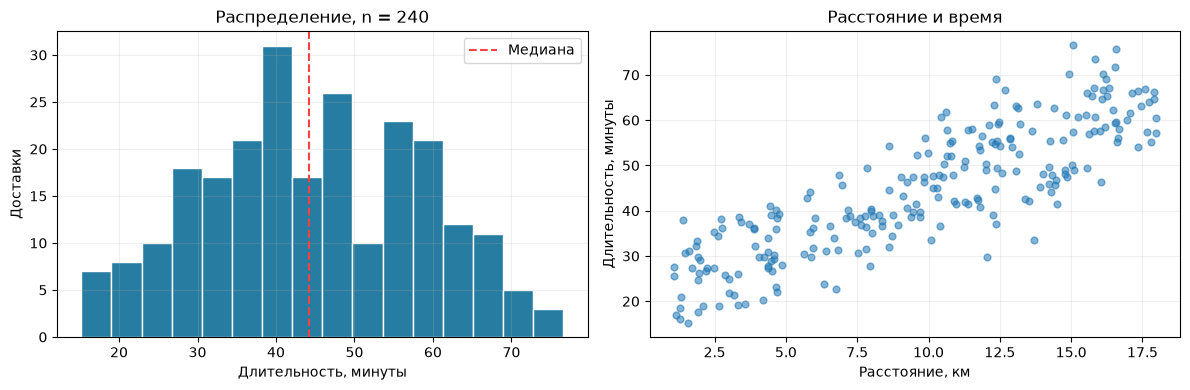

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(deliveries["delivery_minutes"], bins=16, color="#277DA1", edgecolor="white")
axes[0].axvline(deliveries["delivery_minutes"].median(), color="#F94144", linestyle="--", label="Медиана")
axes[0].set(xlabel="Длительность, минуты", ylabel="Доставки", title="Распределение, n = 240")
axes[0].legend()
axes[1].scatter(deliveries["distance_km"], deliveries["delivery_minutes"], alpha=0.55, s=24)
axes[1].set(xlabel="Расстояние, км", ylabel="Длительность, минуты", title="Расстояние и время")
plt.tight_layout()
plt.show()


## 3. seaborn: групповой scatter и boxplot

        Разделим время пик/вне пика. Boxplot показывает медиану, квартильный интервал и точки
        за пределами стандартных усов; эти точки не автоматически ошибочные.
        В сопроводительной таблице оставим n, среднее, медиану и p90.


,n,mean,median,p90
traffic,,,,
off_peak,126,41.05,41.15,57.86
peak,114,48.57,49.82,66.59


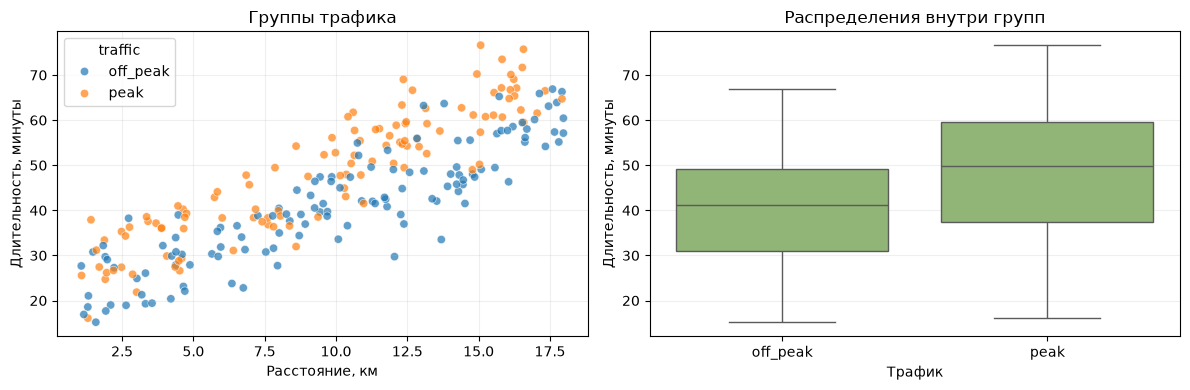

In [4]:
traffic_summary = deliveries.groupby("traffic").agg(
    n=("delivery_id", "size"), mean=("delivery_minutes", "mean"),
    median=("delivery_minutes", "median"), p90=("delivery_minutes", lambda s: s.quantile(0.9)))
display(traffic_summary.round(2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=deliveries, x="distance_km", y="delivery_minutes", hue="traffic", alpha=0.7, ax=axes[0])
axes[0].set(xlabel="Расстояние, км", ylabel="Длительность, минуты", title="Группы трафика")
sns.boxplot(data=deliveries, x="traffic", y="delivery_minutes", color="#90BE6D", ax=axes[1])
axes[1].set(xlabel="Трафик", ylabel="Длительность, минуты", title="Распределения внутри групп")
plt.tight_layout()
plt.show()
assert traffic_summary["n"].sum() == len(deliveries)


## 4. Plotly: интерактивное исследование тех же данных

        Наведите курсор, чтобы увидеть ID, погоду и нагрузку. Легенда позволяет скрывать группы;
        двойной щелчок возвращает масштаб. Используем `plotly_mimetype`: данные и спецификация
        сохраняются в notebook, а JupyterLab/VS Code используют свой renderer.
        Статические графики выше остаются читаемыми в просмотрщиках без Plotly.


In [5]:
interactive = px.scatter(
    deliveries, x="distance_km", y="delivery_minutes", color="traffic",
    hover_data=["delivery_id", "weather", "batch_orders"],
    labels={"distance_km": "Расстояние, км", "delivery_minutes": "Длительность, минуты", "traffic": "Трафик"},
    title="Синтетические доставки: изучите отдельные наблюдения", template="plotly_white")
# Явный MIME renderer не подключает внешнюю CDN-библиотеку.
interactive.show(renderer="plotly_mimetype")
assert sum(len(trace.x) for trace in interactive.data) == len(deliveries)


## 5. Автономный HTML и проверка экспорта

        Для отправки графика вне notebook можно сохранить HTML с JavaScript внутри файла:
        `include_plotlyjs=True`. Это увеличивает файл, зато для открытия не нужен интернет.
        Здесь демонстрация идёт во временной папке; для собственного отчёта выберите свою папку результатов.


In [6]:
with TemporaryDirectory() as temp_dir:
    html_path = Path(temp_dir) / "delivery_scatter.html"
    interactive.write_html(html_path, include_plotlyjs=True, full_html=True, auto_open=False)
    html = html_path.read_text(encoding="utf-8")
    assert "Plotly.newPlot" in html and html_path.stat().st_size > 1000000
    # Нет внешнего script src: библиотека включена в этот HTML.
    from html.parser import HTMLParser
    class ScriptSources(HTMLParser):
        def __init__(self):
            super().__init__()
            self.sources = []
        def handle_starttag(self, tag, attrs):
            if tag == "script":
                self.sources.extend(value for key, value in attrs if key == "src")
    parser = ScriptSources()
    parser.feed(html)
    assert not parser.sources
    print("Автономный HTML сформирован:", round(html_path.stat().st_size / 1024 / 1024, 2), "MiB")


Автономный HTML сформирован: 4.61 MiB


## 6. Pearson и Spearman

        Pearson измеряет линейную связь:
        $r=\frac{\sum_i(x_i-\bar{x})(y_i-\bar{y})}{\sqrt{\sum_i(x_i-\bar{x})^2\sum_i(y_i-\bar{y})^2}}$.
        Spearman применяет корреляцию к рангам и отражает монотонную связь.
        Ни одна из этих величин не доказывает причинность; коэффициент также не заменяет scatter.


In [7]:
numeric = deliveries[["distance_km", "batch_orders", "delivery_minutes"]]
pearson = numeric.corr(method="pearson")
spearman = numeric.corr(method="spearman")
display(pearson.round(3))
display(spearman.round(3))
x = numeric["distance_km"].to_numpy()
y = numeric["delivery_minutes"].to_numpy()
manual_r = ((x - x.mean()) * (y - y.mean())).sum() / np.sqrt(((x - x.mean()) ** 2).sum() * ((y - y.mean()) ** 2).sum())
assert np.isclose(manual_r, pearson.loc["distance_km", "delivery_minutes"])
assert np.allclose(np.diag(pearson), 1) and np.allclose(pearson, pearson.T)


,distance_km,batch_orders,delivery_minutes
distance_km,1.000,0.128,0.854
batch_orders,0.128,1.000,0.296
delivery_minutes,0.854,0.296,1.000


,distance_km,batch_orders,delivery_minutes
distance_km,1.000,0.132,0.866
batch_orders,0.132,1.000,0.284
delivery_minutes,0.866,0.284,1.000


## 7. Heatmap и нелинейный контрпример

        У корреляции диапазон от −1 до 1, поэтому сохраняем общую цветовую шкалу.
        Низкая корреляция не означает отсутствие зависимости: симметричная парабола —
        детерминированная зависимость с почти нулевым Pearson.


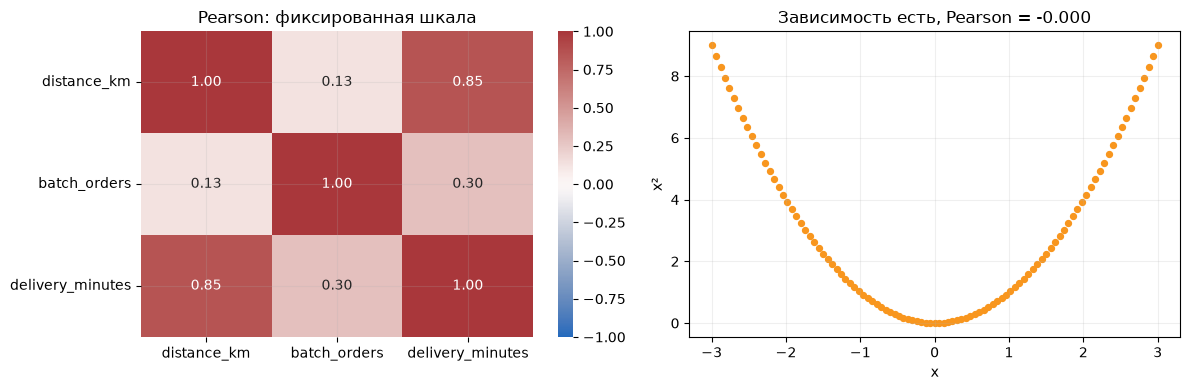

In [8]:
nonlinear_x = np.linspace(-3, 3, 101)
nonlinear_y = nonlinear_x ** 2
nonlinear_r = np.corrcoef(nonlinear_x, nonlinear_y)[0, 1]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(pearson, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0, cmap="vlag", ax=axes[0])
axes[0].set_title("Pearson: фиксированная шкала")
axes[1].scatter(nonlinear_x, nonlinear_y, s=18, color="#F8961E")
axes[1].set(xlabel="x", ylabel="x²", title=f"Зависимость есть, Pearson = {nonlinear_r:.3f}")
plt.tight_layout()
plt.show()
assert abs(nonlinear_r) < 1e-10


## 8. Смешение групп может перевернуть знак

        Отдельный учебный файл содержит медленные короткие маршруты по плотному центру и
        быстрые длинные маршруты по скоростной дороге. Внутри каждого типа увеличение дистанции
        увеличивает время, но смешанная таблица может показать отрицательную связь.
        Не следует переводить такое наблюдение в совет «чем дальше ехать, тем быстрее доедем».


,within_group_pearson
dense_center,0.947166
express_road,0.958351


Общая корреляция: -0.744


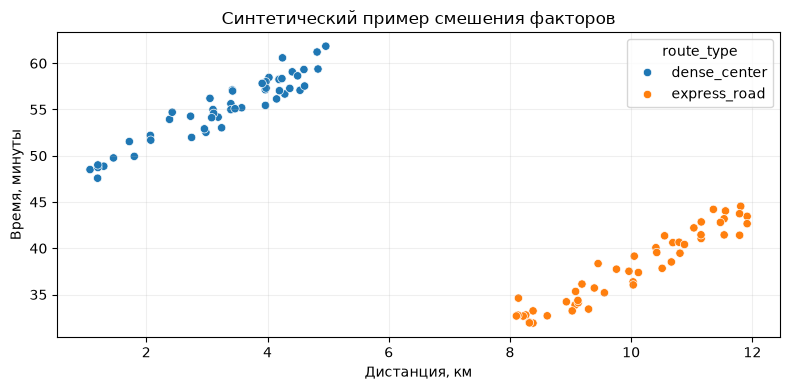

In [9]:
confounded = pd.read_csv(DATA_DIR / "confounding_demo.csv")
overall_r = confounded["distance_km"].corr(confounded["minutes"])
grouped_r = pd.Series({name: g["distance_km"].corr(g["minutes"])
                       for name, g in confounded.groupby("route_type")}, name="within_group_pearson")
display(grouped_r.to_frame())
print("Общая корреляция:", round(overall_r, 3))
assert overall_r < 0 and grouped_r.gt(0).all()
fig, ax = plt.subplots()
sns.scatterplot(data=confounded, x="distance_km", y="minutes", hue="route_type", ax=ax)
ax.set(xlabel="Дистанция, км", ylabel="Время, минуты", title="Синтетический пример смешения факторов")
plt.tight_layout()
plt.show()


## 9. Сравниваем группы с одинаковым определением показателя

        Добавим долю доставок дольше 60 минут. Порог — учебное условие. Процент всегда сопровождаем
        числителем и знаменателем. В реальном отчёте нужно уточнить, одинаково ли собираются
        наблюдения в разных группах и нет ли пропущенных доставок.


In [10]:
deliveries = deliveries.assign(over_60=deliveries["delivery_minutes"] > 60)
report = deliveries.groupby(["traffic", "weather"]).agg(
    n=("delivery_id", "size"), over_60_n=("over_60", "sum"),
    over_60_share=("over_60", "mean"), median_minutes=("delivery_minutes", "median"),
    median_distance=("distance_km", "median"))
display(report.round(3))
assert np.allclose(report["over_60_share"], report["over_60_n"] / report["n"])


n  over_60_n  over_60_share  median_minutes  \
traffic  weather                                                 
off_peak dry      91          4          0.044           40.53   
         rain     35          6          0.171           44.48   
peak     dry      89         17          0.191           47.95   
         rain     25         11          0.440           56.10   

                  median_distance  
traffic  weather                   
off_peak dry                10.40  
         rain                9.26  
peak     dry                10.36  
         rain               10.42

## 10. Формулируем вывод без лишней уверенности

        Хорошая структура: **наблюдение с числом → ограничение → следующий проверяемый вопрос**.
        Например: «В этой выборке медиана в группе X равна ... при n=...; группы различаются
        длиной маршрута, поэтому это не оценка эффекта трафика; сравним похожие маршруты».
        Не называем различие статистически значимым: в этой неделе статистический тест не проводился.


In [11]:
for name, row in traffic_summary.iterrows():
    print(f"{name}: n={int(row['n'])}, медиана={row['median']:.1f} мин, p90={row['p90']:.1f} мин.")
print("Ограничение: данные синтетические; показанные отношения заданы генератором.")
print("Следующий вопрос: сохраняется ли различие при одинаковом расстоянии и погоде?")


off_peak: n=126, медиана=41.1 мин, p90=57.9 мин.
peak: n=114, медиана=49.8 мин, p90=66.6 мин.
Ограничение: данные синтетические; показанные отношения заданы генератором.
Следующий вопрос: сохраняется ли различие при одинаковом расстоянии и погоде?


## Документация и дальнейшее чтение

- [Matplotlib: pyplot tutorial](https://matplotlib.org/stable/tutorials/pyplot.html)
- [seaborn: статистические зависимости](https://seaborn.pydata.org/tutorial/relational.html)
- [Plotly: отображение фигур](https://plotly.com/python/renderers/)
- [Plotly: автономный HTML](https://plotly.com/python/interactive-html-export/)

Код, объяснения и синтетические примеры в этой лабораторной подготовлены для курса; это не копия университетского ноутбука. Дополнительные лекции находятся в `../presentations/`. Документация проверена 18 октября 2026 года; версии среды закреплены на уровне репозитория.
